In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.linear_model import LinearRegression
%matplotlib inline


In [2]:
df = pd.read_csv('house_price.csv')
df

,location,sqft,beds,baths,year_built,price
0,Chicago,1360,2,3,1973,337109
1,Phoenix,4272,2,1,1995,874820
2,New York,3592,4,1,2002,775539
3,Phoenix,966,5,4,2009,288994
4,Houston,4926,3,3,2012,1060183
...,...,...,...,...,...,...
95,New York,1528,6,5,2018,447388
96,Chicago,1002,5,3,1971,282632
97,New York,4993,4,4,2016,1071607
98,New York,1370,2,1,1975,253317


In [3]:
df.columns

Index(['location', 'sqft', 'beds', 'baths', 'year_built', 'price'], dtype='object')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   location    100 non-null    object
 1   sqft        100 non-null    int64 
 2   beds        100 non-null    int64 
 3   baths       100 non-null    int64 
 4   year_built  100 non-null    int64 
 5   price       100 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 4.8+ KB


In [5]:
#Check for null values
df.isnull().sum()

location      0
sqft          0
beds          0
baths         0
year_built    0
price         0
dtype: int64

In [6]:
#Check for dupilcates vaues in list
df.duplicated().sum()

np.int64(0)

In [7]:
df.head()

,location,sqft,beds,baths,year_built,price
0,Chicago,1360,2,3,1973,337109
1,Phoenix,4272,2,1,1995,874820
2,New York,3592,4,1,2002,775539
3,Phoenix,966,5,4,2009,288994
4,Houston,4926,3,3,2012,1060183


In [8]:
#Check for negative values in the numeric columns
numeric_columns=df.select_dtypes(include=['number']).columns

negative_values=(df[numeric_columns]<0).sum()

print(f"Negative values in the numeric columns: {negative_values}")

Negative values in the numeric columns: sqft          0
beds          0
baths         0
year_built    0
price         0
dtype: int64


In [9]:
#Select numeric and non numerice columns
numeric_cols =df.select_dtypes(include=[np.number]).columns
non_numeric_cols=df.select_dtypes(exclude=[np.number]).columns

print(f"Numeric columns: {numeric_cols}")
print('***'*20)
print(f"Non numeric columns: {non_numeric_cols}")

Numeric columns: Index(['sqft', 'beds', 'baths', 'year_built', 'price'], dtype='object')
************************************************************
Non numeric columns: Index(['location'], dtype='object')


In [10]:
num_cols=['sqft', 'beds', 'baths', 'year_built']
cat_cols=['location']

In [11]:
#one hot encoding

encoder =OneHotEncoder(sparse_output=False)
x_encode = encoder.fit_transform(df[cat_cols])
encoded_cols=encoder.get_feature_names_out(cat_cols)
x_encoded_df=pd.DataFrame(x_encode,columns=encoded_cols)
x_encoded_df


,location_Chicago,location_Houston,location_Los Angeles,location_New York,location_Phoenix
0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,0.0
...,...,...,...,...,...
95,0.0,0.0,0.0,1.0,0.0
96,1.0,0.0,0.0,0.0,0.0
97,0.0,0.0,0.0,1.0,0.0
98,0.0,0.0,0.0,1.0,0.0


In [12]:
df[num_cols].head()

,sqft,beds,baths,year_built
0,1360,2,3,1973
1,4272,2,1,1995
2,3592,4,1,2002
3,966,5,4,2009
4,4926,3,3,2012


In [13]:
#Scaling z-scaling normalization
scaler = StandardScaler()
x_scaled=scaler.fit_transform(df[num_cols])
x_scaled
x_scaled_df=pd.DataFrame(x_scaled,columns=num_cols)
x_scaled_df.head()

,sqft,beds,baths,year_built
0,-1.031135,-0.850402,0.079847,-0.680176
1,1.261081,-0.850402,-1.371908,0.376595
2,0.725811,0.291077,-1.371908,0.712840
3,-1.341277,0.861817,0.805724,1.049086
4,1.775885,-0.279662,0.079847,1.193191


In [14]:
df.head()


,location,sqft,beds,baths,year_built,price
0,Chicago,1360,2,3,1973,337109
1,Phoenix,4272,2,1,1995,874820
2,New York,3592,4,1,2002,775539
3,Phoenix,966,5,4,2009,288994
4,Houston,4926,3,3,2012,1060183


In [15]:
df_final= pd.concat( [x_encoded_df.reset_index(drop=True),x_scaled_df.reset_index(drop=True)],axis=1)
df_final.head()

,location_Chicago,location_Houston,location_Los Angeles,location_New York,location_Phoenix,sqft,beds,baths,year_built
0,1.0,0.0,0.0,0.0,0.0,-1.031135,-0.850402,0.079847,-0.680176
1,0.0,0.0,0.0,0.0,1.0,1.261081,-0.850402,-1.371908,0.376595
2,0.0,0.0,0.0,1.0,0.0,0.725811,0.291077,-1.371908,0.712840
3,0.0,0.0,0.0,0.0,1.0,-1.341277,0.861817,0.805724,1.049086
4,0.0,1.0,0.0,0.0,0.0,1.775885,-0.279662,0.079847,1.193191


In [16]:
df_final.columns

Index(['location_Chicago', 'location_Houston', 'location_Los Angeles',
       'location_New York', 'location_Phoenix', 'sqft', 'beds', 'baths',
       'year_built'],
      dtype='object')

In [17]:
#Separate Features from Target columns
x=df_final[['location_Chicago', 'location_Houston', 'location_Los Angeles',
       'location_New York', 'location_Phoenix', 'sqft', 'beds', 'baths',
       'year_built']]
y=df['price']

x

y


0      337109
1      874820
2      775539
3      288994
4     1060183
       ...   
95     447388
96     282632
97    1071607
98     253317
99    1128153
Name: price, Length: 100, dtype: int64

In [18]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.3,random_state=42)

In [19]:
print(len(x_train))
print(len(x_test))

70
30


In [20]:
x_train

,location_Chicago,location_Houston,location_Los Angeles,location_New York,location_Phoenix,sqft,beds,baths,year_built
11,0.0,0.0,1.0,0.0,0.0,0.174010,0.861817,0.079847,0.953016
47,0.0,0.0,0.0,1.0,0.0,1.451574,-1.421141,0.805724,0.616770
85,1.0,0.0,0.0,0.0,0.0,-1.550662,1.432556,0.805724,-1.784983
28,0.0,0.0,0.0,0.0,1.0,-0.710760,0.291077,0.805724,-0.584106
93,0.0,0.0,0.0,1.0,0.0,0.409372,-0.279662,0.805724,1.241226
...,...,...,...,...,...,...,...,...,...
60,0.0,0.0,0.0,1.0,0.0,1.674341,-1.421141,0.079847,0.760875
71,0.0,0.0,0.0,0.0,1.0,-1.409760,-1.421141,-1.371908,0.664805
14,0.0,0.0,0.0,1.0,0.0,0.956449,0.291077,0.079847,-0.680176
92,0.0,1.0,0.0,0.0,0.0,-0.472250,-0.279662,0.805724,1.097121


In [21]:
model =LinearRegression()


In [22]:
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [23]:
model.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [24]:
y_hat = model.predict(x_test)
y_hat

array([ 548327.76184051,  778686.38702127,  930278.50940999,
        681185.47922803,  449882.0568351 ,  197576.06445664,
        374940.01465102,  296080.27456665,  346745.5445252 ,
        318996.44718477,  390857.25678764,  770317.22771811,
        533997.50505175,  310264.94396324,  681010.06028437,
       1056146.88227539,  631929.5637514 ,  566927.96256823,
        649328.47489779,  883571.24380024,  828490.54373648,
        902627.0665781 ,  774133.57043103,  676350.0621662 ,
        364199.23278928, 1013257.83499778,  498189.2998346 ,
        274024.83145885,  506349.39973298,  266403.3498989 ])

In [25]:
mse = mean_squared_error(y_test,y_hat)
print(f'MSE = {mse}')

MSE = 360433498.0383933


In [26]:
r2=r2_score(y_test,y_hat)
print(f'R2 score: {r2:.2f}')

R2 score: 0.99


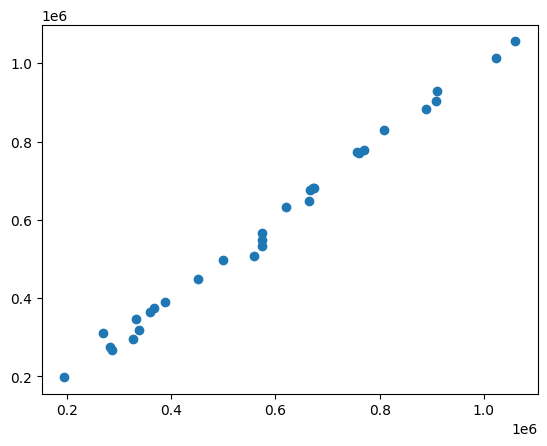

In [27]:
plt.scatter(y_test,y_hat)
plt.show()

In [28]:
#save the model
with open('model.pkl','wb') as f:
    pickle.dump({

        'model':model,
        'encoder':encoder,
        'scaler':scaler,
        'num_cols':num_cols,
        'cat_cols':cat_cols

    },f)
    print('model saved')

model saved
